# Análisis de la corrida final ($N = 5\times10^4$)

Aquí salen las figuras y los números de la sección de resultados del reporte, incluido el estudio de convergencia con $N$. La corrida está en `slurm/datos/xi_estimadores_N50000.npz`: $\hat\xi$ de los cuatro estimadores para $g_0=0$ y $g_0=0.2$, $\alpha=1$ y $3$, en 26 *bins* de 20 a 150 $h^{-1}$Mpc. Se generó con las funciones de `covarianza_test.ipynb`; `slurm/farm.py --prueba base 0 N --independientes` la reproduce bit a bit.

Los errores se estiman con *bootstrap* sobre las realizaciones (200 remuestreos).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, 'slurm')
from farm import espectro, xi_teo

plt.rcParams['font.size'] = 14
FIG = 'reporte/images'

d = np.load('slurm/datos/xi_estimadores_N50000.npz')
r = d['r']
r_edges = np.arange(20, 155, 5)
G0, EST, alphas = [0.0, 0.2], ['PH', 'DP', 'Ham', 'LS'], [1, 3]
xi = {(g0, e, a): d[f'{g0}_{e}_{a}'] for g0 in G0 for e in EST for a in alphas}
Nreal = len(xi[0.0, 'LS', 3])
print(f'N = {Nreal} realizaciones por modelo, {len(r)} bins')

N = 50000 realizaciones por modelo, 26 bins


## 1. $\xi$ teórico

El espectro, la amplitud de la dilución y $\xi(r)$ salen de las mismas funciones que usa `farm.py`.

In [2]:
k, P_L, ratio = espectro()
P = {0.0: P_L, 0.2: ratio*P_L}
print(f'A = P_dil/P_LCDM = {ratio:.4f}')
xi_t = {g0: xi_teo(r, k, P[g0]) for g0 in G0}

A = P_dil/P_LCDM = 0.7999


## 2. Promedio de los estimadores

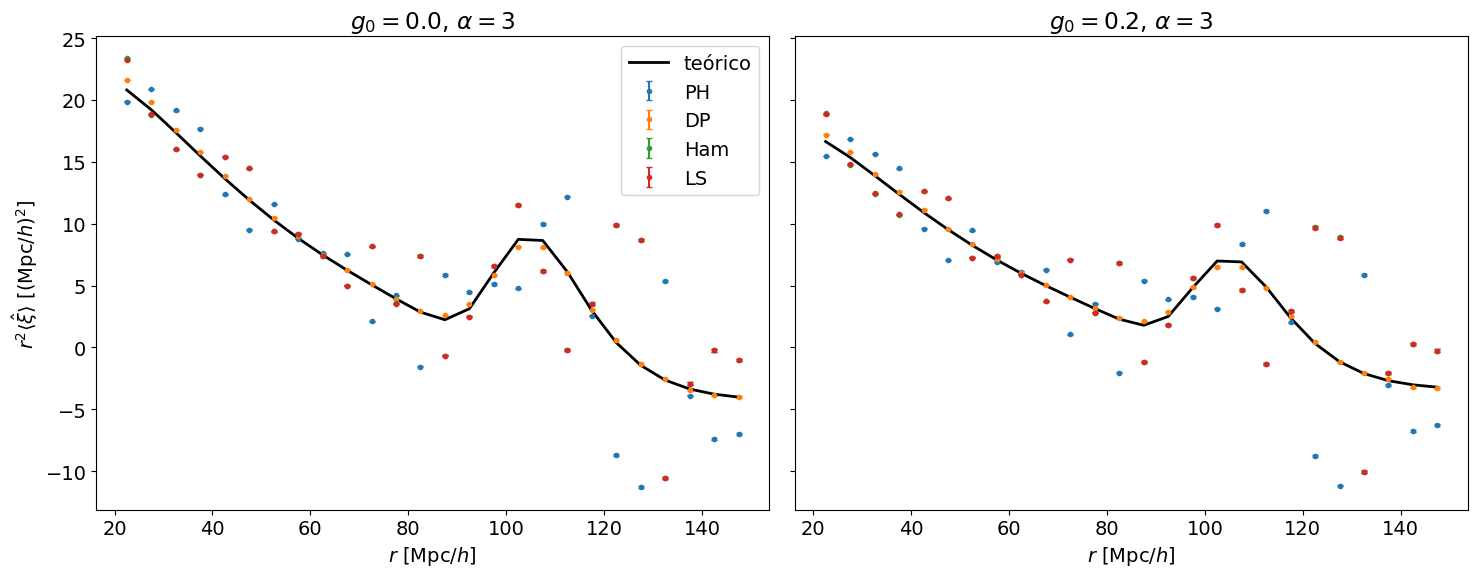

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, g0 in zip(axs, G0):
    for e in EST:
        X = xi[g0, e, 3]
        ax.errorbar(r, r**2*X.mean(0), r**2*X.std(0)/np.sqrt(Nreal), fmt='o', ms=3, capsize=2, label=e)
    ax.plot(r, r**2*xi_t[g0], 'k-', lw=2, label='teórico')
    ax.set(xlabel='$r$ [Mpc/$h$]', title=rf'$g_0={g0}$, $\alpha=3$')
axs[0].set_ylabel(r'$r^2\langle\hat\xi\rangle$ [(Mpc/$h$)$^2$]')
axs[0].legend()
fig.tight_layout()
fig.savefig(f'{FIG}/xi_promedio.png', dpi=100, bbox_inches='tight')
plt.show()

In [4]:
# sesgo del catálogo aleatorio fijo: desviación del teórico y estimación eps ~ sqrt(2V/(N_R^2 V_i))
V, ND = 1000.0**3, 5e-5*1000.0**3
Vi = 4*np.pi/3*(r_edges[1:]**3 - r_edges[:-1]**3)
m = (r > 120) & (r < 130)
for e in ['PH', 'LS']:
    dev = r**2*(xi[0.0, e, 3].mean(0) - xi_t[0.0])
    print(f'{e}: r²(<xi> - xi_teo) en 120-130 Mpc/h = {np.round(dev[m], 1)}')
eps = np.sqrt(2*V/((3*ND)**2*Vi))
print(f'r² eps (alpha=3) en r = {r[m]} : {np.round(r[m]**2*eps[m], 1)}')

PH: r²(<xi> - xi_teo) en 120-130 Mpc/h = [-9.1 -9.9]
LS: r²(<xi> - xi_teo) en 120-130 Mpc/h = [ 9.5 10.1]
r² eps (alpha=3) en r = [122.5 127.5] : [4.6 4.8]


## 3. Matrices de correlación

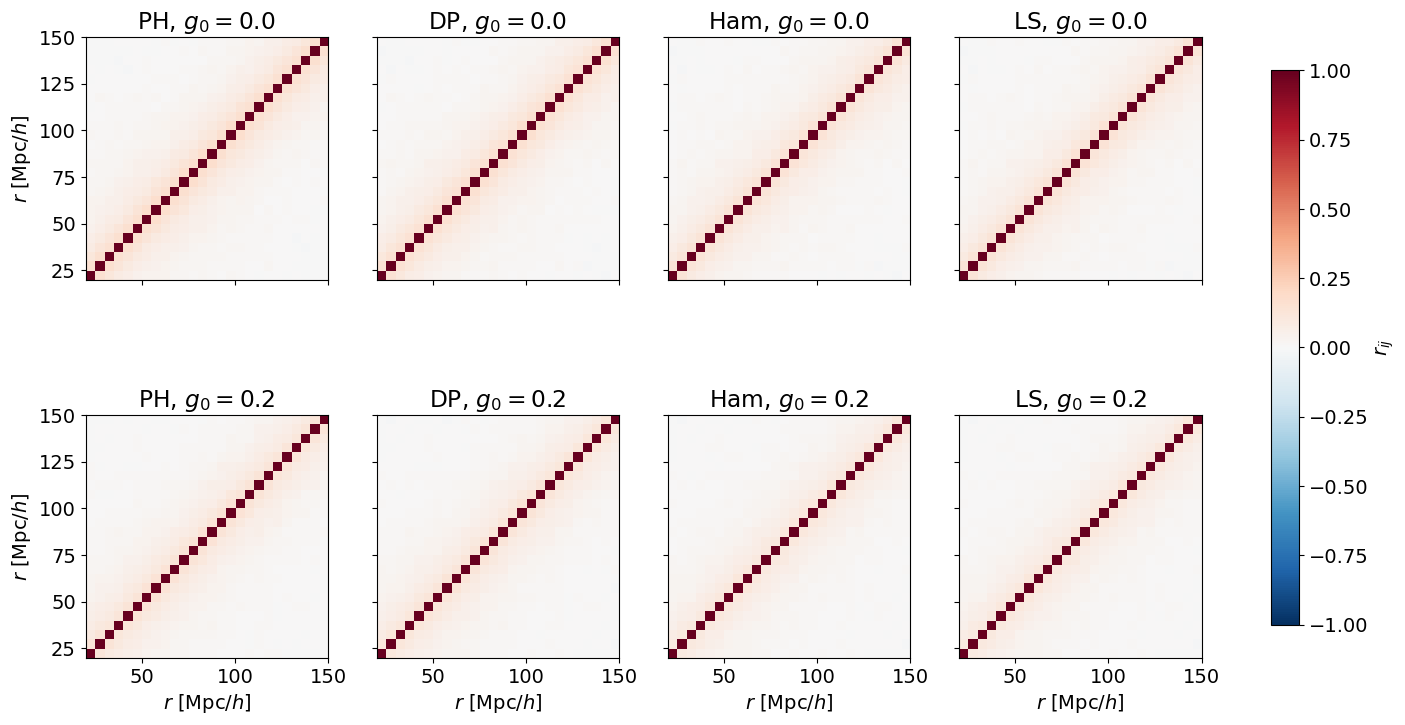

In [5]:
fig, axs = plt.subplots(2, 4, figsize=(18, 9), sharex=True, sharey=True)
for row, g0 in zip(axs, G0):
    for ax, e in zip(row, EST):
        im = ax.imshow(np.corrcoef(xi[g0, e, 3], rowvar=False), origin='lower', cmap='RdBu_r',
                       vmin=-1, vmax=1, extent=[r_edges[0], r_edges[-1], r_edges[0], r_edges[-1]])
        ax.set_title(rf'{e}, $g_0={g0}$')
for ax in axs[1]:
    ax.set_xlabel('$r$ [Mpc/$h$]')
for ax in axs[:, 0]:
    ax.set_ylabel('$r$ [Mpc/$h$]')
fig.colorbar(im, ax=axs, shrink=0.8, label='$r_{ij}$')
fig.savefig(f'{FIG}/matrices_correlacion.png', dpi=100, bbox_inches='tight')
plt.show()

## 4. Comparación entre estimadores

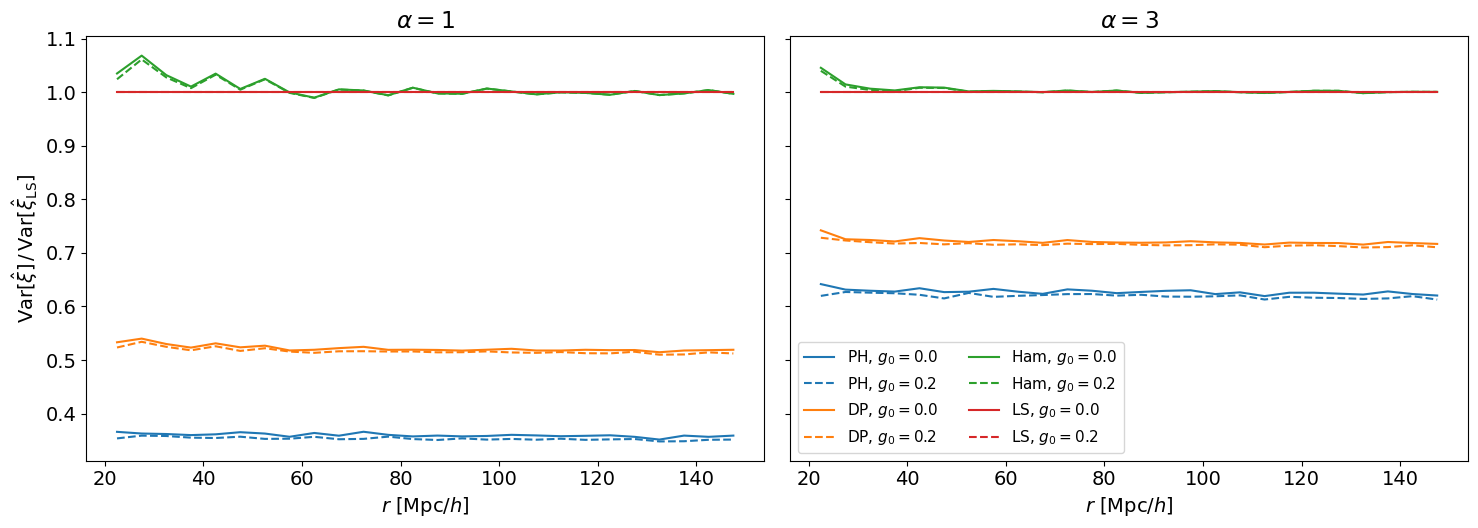

In [6]:
C = {key: np.cov(xi[key], rowvar=False) for key in xi}

fig, axs = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, a in zip(axs, alphas):
    for c, e in enumerate(EST):
        for g0, ls in zip(G0, ['-', '--']):
            ax.plot(r, np.diag(C[g0, e, a])/np.diag(C[g0, 'LS', a]), ls, color=f'C{c}',
                    label=f'{e}, $g_0={g0}$')
    ax.set(xlabel='$r$ [Mpc/$h$]', title=rf'$\alpha={a}$')
axs[0].set_ylabel(r'${\rm Var}[\hat\xi]\,/\,{\rm Var}[\hat\xi_{\rm LS}]$')
axs[1].legend(fontsize=11, ncol=2)
fig.tight_layout()
fig.savefig(f'{FIG}/varianza_estimadores.png', dpi=100, bbox_inches='tight')
plt.show()

## 5. Comparación entre modelos

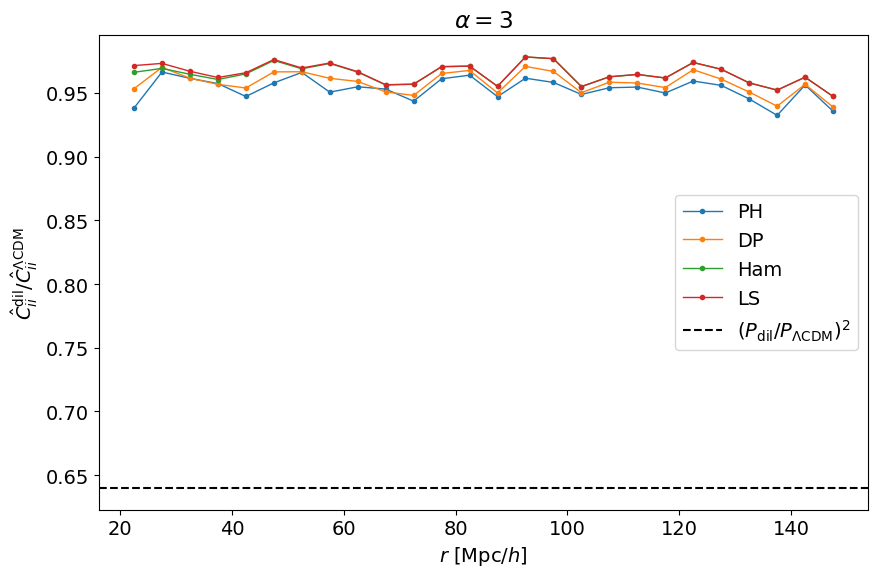

In [7]:
plt.figure(figsize=(9, 6))
for e in EST:
    plt.plot(r, np.diag(C[0.2, e, 3])/np.diag(C[0.0, e, 3]), '-o', ms=3, lw=1, label=e)
plt.axhline(ratio**2, color='k', ls='--', label=r'$(P_{\rm dil}/P_{\Lambda\rm CDM})^2$')
plt.xlabel('$r$ [Mpc/$h$]')
plt.ylabel(r'$\hat C_{ii}^{\rm dil}/\hat C_{ii}^{\Lambda\rm CDM}$')
plt.title(r'$\alpha=3$')
plt.legend()
plt.tight_layout()
plt.savefig(f'{FIG}/cociente_modelos.png', dpi=100, bbox_inches='tight')
plt.show()

## 6. Números y convergencia con $N$

Cada realización usa la semilla $s$, así que las primeras $N$ de la corrida son exactamente una corrida con $N$ realizaciones (se comprobó con las de $N=1000$, $5000$ y $20\,000$). Calculo todas las cantidades para varios $N$, con su error de *bootstrap*; las de $N=5\times10^4$ son los números del reporte.

In [8]:
rangos = [(20, 60), (60, 100), (100, 155)]

def cantidades(ix):
    v = {key: xi[key][ix].var(0, ddof=1) for key in xi}
    q = {}
    for a in alphas:
        for g0 in G0:
            for e in ['PH', 'DP', 'Ham']:
                q[f'Var {e}/LS, a={a}, g0={g0}'] = np.mean(v[g0, e, a]/v[g0, 'LS', a])
        for e in EST:
            q[f'C_dil/C_LCDM {e}, a={a}'] = np.mean(v[0.2, e, a]/v[0.0, e, a])
    for e in ['PH', 'LS']:
        c = v[0.2, e, 3]/v[0.0, e, 3]
        for lo, hi in rangos:
            q[f'C_dil/C_LCDM {e}, a=3, r={lo}-{hi}'] = c[(r >= lo) & (r < hi)].mean()
    for g0 in G0:
        q[f'r_(i,i+1) LS, g0={g0}'] = np.diag(np.corrcoef(xi[g0, 'LS', 3][ix], rowvar=False), 1).mean()
    q['r_(i,i+1) dil/LCDM'] = q['r_(i,i+1) LS, g0=0.2']/q['r_(i,i+1) LS, g0=0.0']
    return q

Ns = [100, 1000, 5000, 20000, 50000]
rng = np.random.default_rng(0)
val, err = {}, {}
for n in Ns:
    val[n] = cantidades(np.arange(n))
    boot = [cantidades(rng.integers(0, n, n)) for _ in range(200)]
    err[n] = {key: np.std([b[key] for b in boot]) for key in val[n]}

for key in val[Nreal]:
    print(f'{key:34s} {val[Nreal][key]:.4f} ± {err[Nreal][key]:.4f}')

Var PH/LS, a=1, g0=0.0             0.3600 ± 0.0005
Var DP/LS, a=1, g0=0.0             0.5219 ± 0.0003
Var Ham/LS, a=1, g0=0.0            1.0076 ± 0.0000
Var PH/LS, a=1, g0=0.2             0.3533 ± 0.0005
Var DP/LS, a=1, g0=0.2             0.5168 ± 0.0003
Var Ham/LS, a=1, g0=0.2            1.0063 ± 0.0000
C_dil/C_LCDM PH, a=1               0.9531 ± 0.0018
C_dil/C_LCDM DP, a=1               0.9616 ± 0.0017
C_dil/C_LCDM Ham, a=1              0.9700 ± 0.0017
C_dil/C_LCDM LS, a=1               0.9712 ± 0.0017
Var PH/LS, a=3, g0=0.0             0.6274 ± 0.0007
Var DP/LS, a=3, g0=0.0             0.7213 ± 0.0004
Var Ham/LS, a=3, g0=0.0            1.0039 ± 0.0000
Var PH/LS, a=3, g0=0.2             0.6195 ± 0.0007
Var DP/LS, a=3, g0=0.2             0.7157 ± 0.0004
Var Ham/LS, a=3, g0=0.2            1.0032 ± 0.0000
C_dil/C_LCDM PH, a=3               0.9531 ± 0.0018
C_dil/C_LCDM DP, a=3               0.9579 ± 0.0018
C_dil/C_LCDM Ham, a=3              0.9646 ± 0.0018
C_dil/C_LCDM LS, a=3           

In [9]:
# exceso de varianza cósmica c en Var_PH/Var_LS = (2 + c)/(2 + 4/alpha + c), y la predicción con dilución
for a in alphas:
    exceso = lambda q: (q*(2 + 4/a) - 2)/(1 - q)
    c0, c2 = exceso(val[Nreal][f'Var PH/LS, a={a}, g0=0.0']), exceso(val[Nreal][f'Var PH/LS, a={a}, g0=0.2'])
    pred = [(2 + cc)/(2 + 4/a + cc) for cc in (ratio**2*c0, ratio*c0)]
    print(f'alpha={a}: c = {c0:.3f} (LCDM), {c2:.3f} (dil.); [A²c, Ac] = [{ratio**2*c0:.3f}, {ratio*c0:.3f}]; '
          f'Var_PH/Var_LS predicho con dilución: {min(pred):.4f}-{max(pred):.4f}, medido {val[Nreal][f"Var PH/LS, a={a}, g0=0.2"]:.4f}')

nb = len(r)
for N in [100, Nreal]:
    print(f'factor de Hartlap (N - n_b - 2)/(N - 1) con N = {N}: {(N - nb - 2)/(N - 1):.5f}')

alpha=1: c = 0.250 (LCDM), 0.185 (dil.); [A²c, Ac] = [0.160, 0.200]; Var_PH/Var_LS predicho con dilución: 0.3506-0.3548, medido 0.3533
alpha=3: c = 0.246 (LCDM), 0.171 (dil.); [A²c, Ac] = [0.157, 0.196]; Var_PH/Var_LS predicho con dilución: 0.6180-0.6223, medido 0.6195
factor de Hartlap (N - n_b - 2)/(N - 1) con N = 100: 0.72727
factor de Hartlap (N - n_b - 2)/(N - 1) con N = 50000: 0.99946


In [10]:
print(f"{'':34s}" + ''.join(f'{f"N={n}":>17s}' for n in Ns))
for key in val[Ns[0]]:
    print(f'{key:34s}' + ''.join(f'{val[n][key]:9.3f}±{err[n][key]:.3f}' for n in Ns))

                                              N=100           N=1000           N=5000          N=20000          N=50000
Var PH/LS, a=1, g0=0.0                0.386±0.013    0.365±0.004    0.359±0.002    0.360±0.001    0.360±0.001
Var DP/LS, a=1, g0=0.0                0.536±0.008    0.526±0.002    0.522±0.001    0.522±0.000    0.522±0.000
Var Ham/LS, a=1, g0=0.0               1.007±0.000    1.007±0.000    1.008±0.000    1.008±0.000    1.008±0.000
Var PH/LS, a=1, g0=0.2                0.369±0.013    0.357±0.004    0.353±0.002    0.353±0.001    0.353±0.000
Var DP/LS, a=1, g0=0.2                0.516±0.007    0.519±0.002    0.517±0.001    0.517±0.001    0.517±0.000
Var Ham/LS, a=1, g0=0.2               1.007±0.000    1.006±0.000    1.006±0.000    1.006±0.000    1.006±0.000
C_dil/C_LCDM PH, a=1                  0.903±0.040    0.961±0.012    0.957±0.006    0.950±0.003    0.953±0.002
C_dil/C_LCDM DP, a=1                  0.912±0.037    0.971±0.013    0.964±0.005    0.960±0.003    0.962±0.002


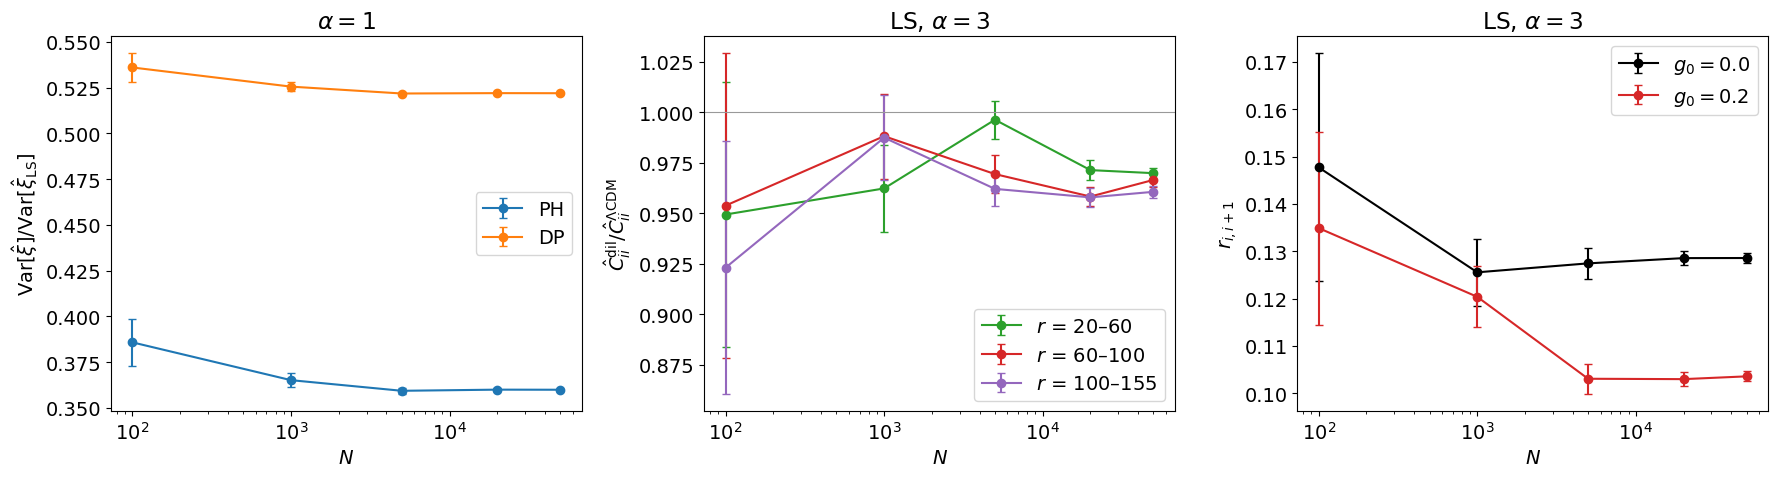

In [11]:
def curva(ax, key, **kw):
    ax.errorbar(Ns, [val[n][key] for n in Ns], [err[n][key] for n in Ns], fmt='o-', capsize=3, **kw)

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for e, c in [('PH', 'C0'), ('DP', 'C1')]:
    curva(axs[0], f'Var {e}/LS, a=1, g0=0.0', color=c, label=e)
axs[0].set(ylabel=r'${\rm Var}[\hat\xi]/{\rm Var}[\hat\xi_{\rm LS}]$', title=r'$\alpha=1$')

for (lo, hi), c in zip(rangos, ['C2', 'C3', 'C4']):
    curva(axs[1], f'C_dil/C_LCDM LS, a=3, r={lo}-{hi}', color=c, label=f'$r$ = {lo}–{hi}')
axs[1].axhline(1, color='0.6', lw=0.8)
axs[1].set(ylabel=r'$\hat C_{ii}^{\rm dil}/\hat C_{ii}^{\Lambda\rm CDM}$', title=r'LS, $\alpha=3$')

for g0, c in [(0.0, 'k'), (0.2, 'C3')]:
    curva(axs[2], f'r_(i,i+1) LS, g0={g0}', color=c, label=f'$g_0={g0}$')
axs[2].set(ylabel='$r_{i,i+1}$', title=r'LS, $\alpha=3$')

for ax in axs:
    ax.set(xscale='log', xlabel='$N$')
    ax.legend()
fig.tight_layout()
fig.savefig(f'{FIG}/convergencia.png', dpi=100, bbox_inches='tight')
plt.show()

Con $N=5000$ el rango 20–60 daba $0.996\pm0.009$ y parecía que el cociente bajaba con $r$, pero era una fluctuación: con $N=5\times10^4$ los tres rangos quedan en $0.970$, $0.967$ y $0.961$ ($\pm0.003$), casi planos.

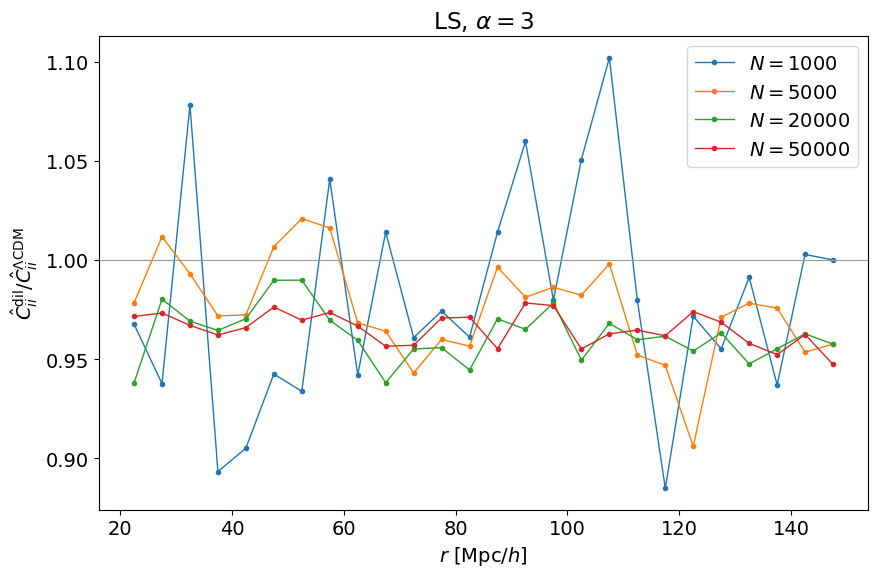

In [12]:
plt.figure(figsize=(9, 6))
for n in Ns[1:]:
    c = xi[0.2, 'LS', 3][:n].var(0, ddof=1)/xi[0.0, 'LS', 3][:n].var(0, ddof=1)
    plt.plot(r, c, '-o', ms=3, lw=1, label=f'$N={n}$')
plt.axhline(1, color='0.6', lw=0.8)
plt.xlabel('$r$ [Mpc/$h$]')
plt.ylabel(r'$\hat C_{ii}^{\rm dil}/\hat C_{ii}^{\Lambda\rm CDM}$')
plt.title(r'LS, $\alpha=3$')
plt.legend()
plt.tight_layout()
plt.savefig(f'{FIG}/cociente_bins.png', dpi=100, bbox_inches='tight')
plt.show()